# 34 · Verificación cruzada de E3·S4 con la matriz C3 (fase 4 del encargo de FE)

Encargo `docs/modeling/fe_hiperparametros.md`, fase 4. El preregistro (`src/modeling/preregistro_fe.py → FASE4`)
se commiteó antes de esta corrida. El protocolo (`protocolo_arquitectura.py`) no cambia. Este notebook solo
orquesta; nada se escribe en `data/`.

- **4.1 Interacción:** no se corre. La fase 3 dejó los hiperparámetros que ya usaba la fase 2; reevaluar las
  familias con ellos repetiría la fase 2 exactamente.
- **4.2** α dentro de la muestra frente a α OOS (C3·S4_s2).
- **4.3** S4_s3 frente a S4_s2 (C3, con la α que salga de la 4.2).
- **4.4** Rangos entre semillas de la configuración final.

Comparaciones del encargo: 17 + 2 = **19**.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.eda.carga import cargar_integrado
from src.modeling import cache_experimentos as cache
from src.modeling import diagnostico_arquitectura as d
from src.modeling import estrategias_horizonte as eh
from src.modeling import experimentos_variables as ev
from src.modeling import fe_hiperparametros as fh
from src.modeling import features_inicio as fi
from src.modeling import preregistro_fe as pr
from src.modeling import protocolo_arquitectura as pa
from src.modeling import salida_probabilistica as sp
from src.modeling.seguimiento_mlflow import registrar_o_avisar
from src.utils.paths import (EXPERIMENTOS_FE_HIPERPARAMETROS, FIGURAS_FE_HIPERPARAMETROS, GOLD_MANIFEST,
                             METRICAS_FE_HIPERPARAMETROS, SILVER_EPI_HISTORICO, SILVER_INTEGRADO)

warnings.filterwarnings("ignore", message=".*mismatched devices.*")
pd.set_option("display.precision", 4)
HUELLA = cache.huella_encargo()
CACHE = EXPERIMENTOS_FE_HIPERPARAMETROS / "cache"
DESTINO4 = EXPERIMENTOS_FE_HIPERPARAMETROS / "fase4"
DESTINO4.mkdir(parents=True, exist_ok=True)

panel = cargar_integrado(SILVER_INTEGRADO)
regla = json.loads(GOLD_MANIFEST.read_text(encoding="utf-8"))["regla_brote"]
ins = fh.insumos(panel, regla)
matrices, serie = ins["matrices"], ins["serie"]
variables_inicio = fi.VariablesInicio(panel, serie, pd.read_csv(SILVER_EPI_HISTORICO, dtype={"ubigeo": "string"}), regla)
COLUMNAS = [*eh.GENERICAS, *fi.COLUMNAS["B3"]]
origenes = variables_inicio.origenes(eh.tabla_origenes(matrices[2]), ["B3"], pd.Timestamp("2021-08-28"))
assert not origenes[COLUMNAS].isna().any().any()
recorte = ev.recorte_robustez(origenes, "primeras_8_semanas_2017")
o_recortados = origenes.loc[~recorte].reset_index(drop=True)
print("matriz C3:", COLUMNAS, "| comparaciones del encargo:", pr.comparaciones()["total_encargo"])

matriz C3: ['hist_lag_a', 'hist_lag_b', 'hist_media_4', 'hist_semanas_pos_4', 'semana_epi_seno', 'semana_epi_coseno', 'propia_semanas_desde_ultimo_caso', 'propia_pendiente_4', 'propia_log_casos_temporada_anterior'] | comparaciones del encargo: 19


In [2]:
pd.Series({k: json.dumps(v, ensure_ascii=False) if isinstance(v, (dict, list)) else v
           for k, v in pr.FASE4.items()}, name="preregistro").to_frame()

,preregistro
fecha,"2026-10-27, antes de cualquier corrida de la f..."
configuracion_de_partida,"C3·S4_s2 (base_6 + B3), hiperparámetros hereda..."
4.1_interaccion,no se corre: los hiperparámetros elegidos en l...
4.2_alfa,"{""candidata"": ""C3·S4_s2 con α OOS"", ""referenci..."
4.3_s4_s3,"{""candidata"": ""C3·S4_s3"", ""referencia"": ""C3·S4..."
4.4_rangos,"mínimo, mediana, máximo y rango de las 5 semil..."
lecturas_que_no_deciden,"[""antelación"", ""recall de brotes nuevos"", ""pos..."
regla,"simétrica del protocolo, 5 semillas, por horiz..."


## 4.2 · α dentro de la muestra frente a α OOS (C3·S4_s2, 5 semillas)

La referencia es la configuración actual (α dentro de la muestra). La candidata estima α con las predicciones
fuera de muestra de los bloques anteriores; 2021 usa el pseudo-bloque `temporada_2020`. El respaldo preregistrado
está en `salida_probabilistica.alfas_oos`.

**Limitación del pseudo-bloque:** 2020 tiene solo 2 semanas brote y cruza el inicio de la pandemia (posible
subregistro, *hipótesis*). La dispersión de una temporada tranquila puede no representar la de una epidémica, y
esa α entra en la cadena de Platt de 2022.

In [3]:
def _evaluar(formulacion, dispersion, o=origenes):
    return ev.evaluar_y_resumir(matrices, serie, columnas=COLUMNAS, origenes=o, formulacion=formulacion, dispersion=dispersion)

ref_42 = cache.cargar_o_calcular("fase4_s4s2_dentro", lambda: _evaluar("S4_s2", "dentro_muestra"), huella=HUELLA, directorio=CACHE)
oos_42 = cache.cargar_o_calcular("fase4_s4s2_oos", lambda: _evaluar("S4_s2", "oos"), huella=HUELLA, directorio=CACHE)
alfas_42 = ev.resumen_alfas(oos_42["alfas"])
print("semillas × bloques × horizontes con respaldo:", int(oos_42["alfas"].respaldo.sum()), "de", len(oos_42["alfas"]))
alfas_42

caché: 'fase4_s4s2_dentro' reutilizada (huella 3941515c661d)
caché: 'fase4_s4s2_oos' reutilizada (huella 3941515c661d)
semillas × bloques × horizontes con respaldo: 30 de 75


,bloque,horizonte,alpha_dentro_muestra,alpha_oos,alpha_usada,semillas_con_respaldo
0,calendario_2025,2,0.7219,0.8405,0.8405,0
1,calendario_2025,3,1.2146,1.4287,1.4287,0
2,calendario_2025,4,1.7957,2.0930,2.0930,0
3,temporada_2021,2,0.5344,62.8914,0.5344,5
4,temporada_2021,3,0.8916,65.5323,0.8916,5
5,temporada_2021,4,1.4042,69.8724,1.4042,5
6,temporada_2022,2,0.8282,6.7825,0.8282,5
7,temporada_2022,3,1.4155,11.3771,1.4155,5
8,temporada_2022,4,2.2902,15.6506,2.2902,5
9,temporada_2023,2,0.7457,1.2417,1.2417,0


In [4]:
oos_42["alfas"].query("respaldo")[["semilla", "bloque", "horizonte", "alpha_dentro_muestra", "alpha_oos", "convergio",
                                    "en_limite", "en_rango", "rango_minimo", "rango_maximo"]] \
    if oos_42["alfas"].respaldo.any() else "ningún bloque usó el respaldo"

,semilla,bloque,horizonte,alpha_dentro_muestra,alpha_oos,convergio,en_limite,en_rango,rango_minimo,rango_maximo
0,17,temporada_2021,2,0.5350,62.5922,True,False,False,0.1070,4.5028
1,17,temporada_2021,3,0.8916,65.2421,True,False,False,0.1783,7.8869
2,17,temporada_2021,4,1.4042,69.2945,True,False,False,0.2808,11.7942
3,17,temporada_2022,2,0.8276,6.7427,True,False,False,0.1070,4.5028
4,17,temporada_2022,3,1.4163,11.2268,True,False,False,0.1783,7.8869
5,17,temporada_2022,4,2.2992,15.4541,True,False,False,0.2808,11.7942
15,29,temporada_2021,2,0.5369,62.9758,True,False,False,0.1074,4.4916
16,29,temporada_2021,3,0.9030,65.5323,True,False,False,0.1806,7.8483
17,29,temporada_2021,4,1.4181,69.8724,True,False,False,0.2836,11.7317
18,29,temporada_2022,2,0.8311,6.8114,True,False,False,0.1074,4.4916


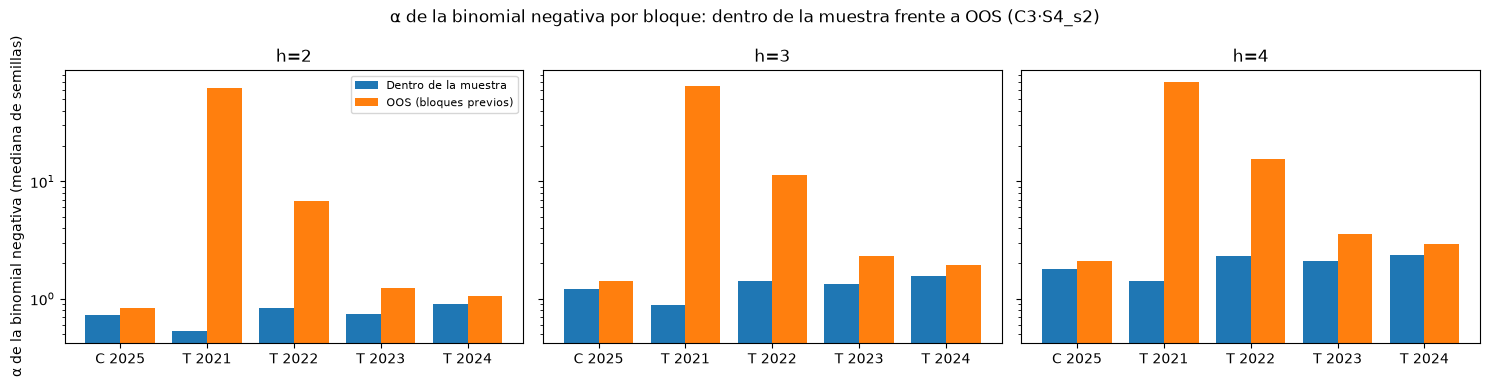

In [5]:
fig = ev.figura_alfas(alfas_42, "α de la binomial negativa por bloque: dentro de la muestra frente a OOS (C3·S4_s2)")
ruta_alfas = FIGURAS_FE_HIPERPARAMETROS / "alfas_fase4.png"
fig.savefig(ruta_alfas, dpi=150, bbox_inches="tight"); plt.show()

In [6]:
veredicto_42 = ev.comparar_familia("alfa_oos", oos_42["evaluaciones"], oos_42["resumen"],
                                   "alfa_dentro", ref_42["evaluaciones"], ref_42["resumen"])
DISPERSION = "oos" if ev.gana_a(veredicto_42) else "dentro_muestra"
COLS_VEREDICTO = ["horizonte", "veredicto", "mejora_f1_050", "empeora_f1_050", "mejora_antelacion", "empeora_antelacion",
                  "vetos", "vetos_contra_referencia", "antelacion_diferencia", "antelacion_ic95_inferior",
                  "antelacion_ic95_superior", "mejora_recall_nuevos", "posible_senal_de_temporada"]
display(veredicto_42[COLS_VEREDICTO])
print("α adoptada:", DISPERSION)

,horizonte,veredicto,mejora_f1_050,empeora_f1_050,mejora_antelacion,empeora_antelacion,vetos,vetos_contra_referencia,antelacion_diferencia,antelacion_ic95_inferior,antelacion_ic95_superior,mejora_recall_nuevos,posible_senal_de_temporada
0,2,empate,False,False,False,False,None,None,-0.0211,-0.0526,0.0000,False,False
1,3,empate,False,False,False,False,None,None,-0.0526,-0.0947,-0.0105,False,False
2,4,empate,False,False,False,False,None,None,-0.0842,-0.1368,-0.0316,False,False


α adoptada: dentro_muestra


In [7]:
def _comparacion(a, b, na, nb):
    t = pd.concat([ev.tabla_metricas(b["resumen"], nb), ev.tabla_metricas(a["resumen"], na)])
    t = t[t.bloque.isin([*pa.BLOQUES_SELECCION, pa.BLOQUE_CONTRASTE])]
    return t

def _lecturas(a, b, na, nb):
    ant = pd.concat({nb: b["resumen"]["antelacion"], na: a["resumen"]["antelacion"]}, names=["variante"]).reset_index(level=0)
    rec = pd.concat({nb: b["resumen"]["recall_por_tipo"], na: a["resumen"]["recall_por_tipo"]}, names=["variante"]).reset_index(level=0)
    return ant, rec

comparacion_42 = _comparacion(oos_42, ref_42, "alfa_oos", "alfa_dentro")
display(comparacion_42.pivot_table(index=["bloque", "horizonte"], columns="variante",
                                   values=["f1_050", "auprc", "brier", "razon_mae", "razon_rmse"]).round(3))
veredicto_42[["horizonte", *[c for c in veredicto_42 if c.startswith(("delta_", "umbral_"))]]].round(4)

auprc                brier           \
variante                 alfa_dentro alfa_oos alfa_dentro alfa_oos   
bloque         horizonte                                             
temporada_2022 2               0.798    0.798       0.052    0.052   
               3               0.782    0.782       0.056    0.056   
               4               0.739    0.739       0.065    0.065   
temporada_2023 2               0.949    0.948       0.061    0.066   
               3               0.931    0.931       0.074    0.085   
               4               0.918    0.918       0.085    0.100   
temporada_2024 2               0.893    0.893       0.076    0.078   
               3               0.866    0.866       0.088    0.091   
               4               0.821    0.821       0.103    0.106   

                              f1_050            razon_mae           \
variante                 alfa_dentro alfa_oos alfa_dentro alfa_oos   
bloque         horizonte                                             
temporada_2022 2               0.728    0.728       0.929    0.929   
               3               0.612    0.612       0.921    0.921   
               4               0.466    0.466       0.947    0.947   
temporada_2023 2               0.856    0.843       1.010    1.010   
               3               0.829    0.778       0.869    0.869   
               4               0.796    0.737       0.796    0.796   
temporada_2024 2               0.813    0.810       1.182    1.182   
               3               0.786    0.780       1.232    1.232   
               4               0.743    0.737       1.300    1.300   

                          razon_rmse           
variante                 alfa_dentro alfa_oos  
bloque         horizonte                       
temporada_2022 2               0.902    0.902  
               3               0.900    0.900  
               4               0.953    0.953  
temporada_2023 2               1.190    1.190  
               3               0.986    0.986  
               4               0.876    0.876  
temporada_2024 2               1.242    1.242  
               3               1.245    1.245  
               4               1.266    1.266

,horizonte,umbral_f1_050_temporada_2022,umbral_f1_050_temporada_2023,umbral_auprc_temporada_2022,umbral_auprc_temporada_2023,umbral_brier_temporada_2022,umbral_brier_temporada_2023,umbral_razon_mae_temporada_2022,umbral_razon_mae_temporada_2023,delta_f1_050_temporada_2022,delta_f1_050_temporada_2023,delta_auprc_temporada_2022,delta_auprc_temporada_2023,delta_brier_temporada_2022,delta_brier_temporada_2023,delta_razon_mae_temporada_2022,delta_razon_mae_temporada_2023
0,2,0.0117,0.0051,0.0034,0.0007,0.0004,0.0006,0.0122,0.0248,0.0,-0.0127,0.0,-0.0003,0.0,0.0051,0.0,0.0
1,3,0.0148,0.0144,0.0030,0.0010,0.0009,0.0012,0.0183,0.0143,0.0,-0.0507,0.0,-0.0003,0.0,0.0110,0.0,0.0
2,4,0.0355,0.0116,0.0038,0.0010,0.0013,0.0017,0.0170,0.0090,0.0,-0.0590,0.0,-0.0003,0.0,0.0151,0.0,0.0


In [8]:
antelacion_42, recall_42 = _lecturas(oos_42, ref_42, "alfa_oos", "alfa_dentro")
display(antelacion_42.pivot_table(index="variante", columns=["horizonte", "bloque"], values="mediana").round(3))
recall_42.query("tipo == 'brote_nuevo'").pivot_table(index="variante", columns=["horizonte", "bloque"], values="recall_mediana").round(3)

horizonte                     2                                               \
bloque      seleccion_2022_2023 temporada_2022 temporada_2023 temporada_2024   
variante                                                                       
alfa_dentro               0.147          0.132          0.158          0.174   
alfa_oos                  0.126          0.132          0.123          0.261   

horizonte                     3                                               \
bloque      seleccion_2022_2023 temporada_2022 temporada_2023 temporada_2024   
variante                                                                       
alfa_dentro               0.126          0.026          0.193          0.391   
alfa_oos                  0.074          0.026          0.105          0.435   

horizonte                     4                                               
bloque      seleccion_2022_2023 temporada_2022 temporada_2023 temporada_2024  
variante                                                                      
alfa_dentro               0.137            0.0          0.228          0.348  
alfa_oos                  0.053            0.0          0.088          0.348

horizonte                 2                                               \
bloque      calendario_2025 temporada_2022 temporada_2023 temporada_2024   
variante                                                                   
alfa_dentro             0.0          0.122          0.128          0.206   
alfa_oos                0.0          0.122          0.105          0.265   

horizonte                 3                                               \
bloque      calendario_2025 temporada_2022 temporada_2023 temporada_2024   
variante                                                                   
alfa_dentro             0.0           0.02          0.140          0.206   
alfa_oos                0.0           0.02          0.058          0.235   

horizonte                 4                                               
bloque      calendario_2025 temporada_2022 temporada_2023 temporada_2024  
variante                                                                  
alfa_dentro             0.0            0.0          0.128          0.176  
alfa_oos                0.0            0.0          0.070          0.235

### Robustez (solo lectura): sin las 8 primeras semanas de orígenes de 2017

In [9]:
rob_ref = cache.cargar_o_calcular("fase4_rob_s4s2_dentro", lambda: _evaluar("S4_s2", "dentro_muestra", o_recortados),
                                  huella=HUELLA, directorio=CACHE)
rob_oos = cache.cargar_o_calcular("fase4_rob_s4s2_oos", lambda: _evaluar("S4_s2", "oos", o_recortados),
                                  huella=HUELLA, directorio=CACHE)
rob_42 = ev.comparar_familia("alfa_oos", rob_oos["evaluaciones"], rob_oos["resumen"],
                             "alfa_dentro", rob_ref["evaluaciones"], rob_ref["resumen"])
signos_42 = pd.concat({"sin_recorte": ev.signos_por_temporada(oos_42["resumen"], ref_42["resumen"]),
                       "sin_8_semanas_2017": ev.signos_por_temporada(rob_oos["resumen"], rob_ref["resumen"])},
                      names=["recorte"]).reset_index(level=0)
display(rob_42[["horizonte", "veredicto"]])
signos_42.pivot_table(index=["horizonte", "bloque"], columns="recorte", values=["delta_f1_050", "delta_antelacion"]).round(3)

caché: 'fase4_rob_s4s2_dentro' reutilizada (huella 3941515c661d)
caché: 'fase4_rob_s4s2_oos' reutilizada (huella 3941515c661d)


,horizonte,veredicto
0,2,empate
1,3,empate
2,4,empate


delta_antelacion                   delta_f1_050  \
recorte                  sin_8_semanas_2017 sin_recorte sin_8_semanas_2017   
horizonte bloque                                                             
2         temporada_2022              0.000       0.000              0.000   
          temporada_2023             -0.018      -0.035             -0.018   
3         temporada_2022              0.000       0.000              0.000   
          temporada_2023             -0.105      -0.088             -0.067   
4         temporada_2022              0.000       0.000              0.000   
          temporada_2023             -0.140      -0.140             -0.144   

                                      
recorte                  sin_recorte  
horizonte bloque                      
2         temporada_2022       0.000  
          temporada_2023      -0.013  
3         temporada_2022       0.000  
          temporada_2023      -0.051  
4         temporada_2022       0.000  
          temporada_2023      -0.059

## 4.3 · S4_s3 frente a S4_s2 (C3, con la α de la 4.2, 5 semillas)

Si empatan, se queda S4_s2 (más simple: no depende del margen de persistencia).

In [10]:
ref_43 = ref_42 if DISPERSION == "dentro_muestra" else oos_42
s3_43 = cache.cargar_o_calcular(f"fase4_s4s3_{DISPERSION}", lambda: _evaluar("S4_s3", DISPERSION), huella=HUELLA, directorio=CACHE)
veredicto_43 = ev.comparar_familia("S4_s3", s3_43["evaluaciones"], s3_43["resumen"],
                                   "S4_s2", ref_43["evaluaciones"], ref_43["resumen"])
FORMULACION_FINAL = "S4_s3" if ev.gana_a(veredicto_43) else "S4_s2"
display(veredicto_43[COLS_VEREDICTO])
print("formulación adoptada:", FORMULACION_FINAL)

caché: 'fase4_s4s3_dentro_muestra' reutilizada (huella 3941515c661d)


,horizonte,veredicto,mejora_f1_050,empeora_f1_050,mejora_antelacion,empeora_antelacion,vetos,vetos_contra_referencia,antelacion_diferencia,antelacion_ic95_inferior,antelacion_ic95_superior,mejora_recall_nuevos,posible_senal_de_temporada
0,2,empate,False,False,False,False,"auprc, brier",None,-0.0316,-0.0842,0.0105,False,False
1,3,empate,False,False,False,False,brier,None,0.0526,-0.0105,0.1158,True,False
2,4,gana,False,False,True,False,NaN,None,0.0947,0.0316,0.1579,False,False


formulación adoptada: S4_s3


In [11]:
comparacion_43 = _comparacion(s3_43, ref_43, "S4_s3", "S4_s2")
display(comparacion_43.pivot_table(index=["bloque", "horizonte"], columns="variante",
                                   values=["f1_050", "auprc", "brier", "razon_mae", "razon_rmse"]).round(3))
veredicto_43[["horizonte", *[c for c in veredicto_43 if c.startswith(("delta_", "umbral_"))]]].round(4)

auprc         brier        f1_050        razon_mae  \
variante                  S4_s2  S4_s3  S4_s2  S4_s3  S4_s2  S4_s3     S4_s2   
bloque         horizonte                                                       
temporada_2022 2          0.798  0.789  0.052  0.053  0.728  0.711     0.929   
               3          0.782  0.781  0.056  0.057  0.612  0.658     0.921   
               4          0.739  0.753  0.065  0.062  0.466  0.546     0.947   
temporada_2023 2          0.949  0.947  0.061  0.062  0.856  0.852     1.010   
               3          0.931  0.928  0.074  0.075  0.829  0.828     0.869   
               4          0.918  0.917  0.085  0.084  0.796  0.803     0.796   
temporada_2024 2          0.893  0.891  0.076  0.076  0.813  0.796     1.182   
               3          0.866  0.870  0.088  0.086  0.786  0.778     1.232   
               4          0.821  0.831  0.103  0.098  0.743  0.745     1.300   

                                razon_rmse         
variante                  S4_s3      S4_s2  S4_s3  
bloque         horizonte                           
temporada_2022 2          1.001      0.902  1.106  
               3          1.021      0.900  1.232  
               4          1.040      0.953  1.380  
temporada_2023 2          0.881      1.190  0.987  
               3          0.808      0.986  0.913  
               4          0.764      0.876  0.852  
temporada_2024 2          1.352      1.242  1.673  
               3          1.515      1.245  1.890  
               4          1.622      1.266  2.014

,horizonte,umbral_f1_050_temporada_2022,umbral_f1_050_temporada_2023,umbral_auprc_temporada_2022,umbral_auprc_temporada_2023,umbral_brier_temporada_2022,umbral_brier_temporada_2023,umbral_razon_mae_temporada_2022,umbral_razon_mae_temporada_2023,delta_f1_050_temporada_2022,delta_f1_050_temporada_2023,delta_auprc_temporada_2022,delta_auprc_temporada_2023,delta_brier_temporada_2022,delta_brier_temporada_2023,delta_razon_mae_temporada_2022,delta_razon_mae_temporada_2023
0,2,0.0117,0.0048,0.0034,0.0010,0.0005,0.0006,0.0122,0.0248,-0.0171,-0.0038,-0.0084,-0.0019,0.0017,0.0015,0.0722,-0.1296
1,3,0.0183,0.0049,0.0040,0.0012,0.0009,0.0006,0.0189,0.0143,0.0467,-0.0010,-0.0007,-0.0025,0.0009,0.0011,0.1007,-0.0601
2,4,0.0355,0.0086,0.0054,0.0016,0.0013,0.0007,0.0279,0.0117,0.0803,0.0065,0.0134,-0.0014,-0.0023,-0.0002,0.0925,-0.0322


In [12]:
antelacion_43, recall_43 = _lecturas(s3_43, ref_43, "S4_s3", "S4_s2")
display(antelacion_43.pivot_table(index="variante", columns=["horizonte", "bloque"], values="mediana").round(3))
recall_43.query("tipo == 'brote_nuevo'").pivot_table(index="variante", columns=["horizonte", "bloque"], values="recall_mediana").round(3)

horizonte                   2                                               \
bloque    seleccion_2022_2023 temporada_2022 temporada_2023 temporada_2024   
variante                                                                     
S4_s2                   0.147          0.132          0.158          0.174   
S4_s3                   0.137          0.132          0.140          0.435   

horizonte                   3                                               \
bloque    seleccion_2022_2023 temporada_2022 temporada_2023 temporada_2024   
variante                                                                     
S4_s2                   0.126          0.026          0.193          0.391   
S4_s3                   0.211          0.105          0.281          0.565   

horizonte                   4                                               
bloque    seleccion_2022_2023 temporada_2022 temporada_2023 temporada_2024  
variante                                                                    
S4_s2                   0.137          0.000          0.228          0.348  
S4_s3                   0.232          0.053          0.351          0.478

horizonte               2                                               \
bloque    calendario_2025 temporada_2022 temporada_2023 temporada_2024   
variante                                                                 
S4_s2                 0.0          0.122          0.128          0.206   
S4_s3                 0.0          0.102          0.116          0.382   

horizonte               3                                               \
bloque    calendario_2025 temporada_2022 temporada_2023 temporada_2024   
variante                                                                 
S4_s2                 0.0          0.020          0.140          0.206   
S4_s3                 0.0          0.082          0.174          0.265   

horizonte               4                                               
bloque    calendario_2025 temporada_2022 temporada_2023 temporada_2024  
variante                                                                
S4_s2                 0.0          0.000          0.128          0.176  
S4_s3                 0.0          0.041          0.163          0.324

In [13]:
rob_ref_43 = rob_ref if DISPERSION == "dentro_muestra" else rob_oos
rob_s3 = cache.cargar_o_calcular(f"fase4_rob_s4s3_{DISPERSION}", lambda: _evaluar("S4_s3", DISPERSION, o_recortados),
                                 huella=HUELLA, directorio=CACHE)
rob_43 = ev.comparar_familia("S4_s3", rob_s3["evaluaciones"], rob_s3["resumen"],
                             "S4_s2", rob_ref_43["evaluaciones"], rob_ref_43["resumen"])
signos_43 = pd.concat({"sin_recorte": ev.signos_por_temporada(s3_43["resumen"], ref_43["resumen"]),
                       "sin_8_semanas_2017": ev.signos_por_temporada(rob_s3["resumen"], rob_ref_43["resumen"])},
                      names=["recorte"]).reset_index(level=0)
display(rob_43[["horizonte", "veredicto"]])
signos_43.pivot_table(index=["horizonte", "bloque"], columns="recorte", values=["delta_f1_050", "delta_antelacion"]).round(3)

caché: 'fase4_rob_s4s3_dentro_muestra' reutilizada (huella 3941515c661d)


,horizonte,veredicto
0,2,empate
1,3,gana
2,4,gana


delta_antelacion                   delta_f1_050  \
recorte                  sin_8_semanas_2017 sin_recorte sin_8_semanas_2017   
horizonte bloque                                                             
2         temporada_2022              0.000       0.000              0.040   
          temporada_2023              0.018      -0.018             -0.001   
3         temporada_2022              0.053       0.079              0.130   
          temporada_2023              0.105       0.088              0.008   
4         temporada_2022              0.026       0.053              0.214   
          temporada_2023              0.140       0.123              0.023   

                                      
recorte                  sin_recorte  
horizonte bloque                      
2         temporada_2022      -0.017  
          temporada_2023      -0.004  
3         temporada_2022       0.047  
          temporada_2023      -0.001  
4         temporada_2022       0.080  
          temporada_2023       0.007

## 4.4 · Configuración final y rangos entre semillas

In [14]:
finales = {("S4_s2", "dentro_muestra"): ref_42, ("S4_s2", "oos"): oos_42, ("S4_s3", DISPERSION): s3_43}
final = finales[(FORMULACION_FINAL, DISPERSION)]
CONFIGURACION_FINAL = {"matriz": "C3 = base_6 + B3", "columnas": COLUMNAS, "estrategia": "E3 (multi_output_tree)",
                       "formulacion": FORMULACION_FINAL, "dispersion": DISPERSION,
                       "hiperparametros": "heredados (fase 3: se queda la base)", "calibracion": "Platt cronológico",
                       "umbral_alerta": pa.UMBRAL_ALERTA}
rangos_44 = ev.rangos_configuracion(final["evaluaciones"])
display(pd.Series(CONFIGURACION_FINAL, name="configuración final").to_frame())
rangos_44.pivot_table(index=["metrica", "bloque"], columns="horizonte", values=["mediana", "rango"]).round(3)

,configuración final
matriz,C3 = base_6 + B3
columnas,"[hist_lag_a, hist_lag_b, hist_media_4, hist_se..."
estrategia,E3 (multi_output_tree)
formulacion,S4_s3
dispersion,dentro_muestra
hiperparametros,heredados (fase 3: se queda la base)
calibracion,Platt cronológico
umbral_alerta,0.5


mediana                rango              
horizonte                        2      3      4      2      3      4
metrica    bloque                                                    
auprc      calendario_2025   0.045  0.098  0.014  0.004  0.005  0.001
           temporada_2022    0.789  0.781  0.753  0.002  0.004  0.005
           temporada_2023    0.947  0.928  0.917  0.001  0.001  0.002
           temporada_2024    0.891  0.870  0.831  0.001  0.001  0.001
brier      calendario_2025   0.004  0.005  0.008  0.000  0.000  0.000
           temporada_2022    0.053  0.057  0.062  0.000  0.000  0.001
           temporada_2023    0.062  0.075  0.084  0.001  0.001  0.001
           temporada_2024    0.076  0.086  0.098  0.001  0.001  0.001
f1_050     calendario_2025   0.000  0.143  0.000  0.000  0.124  0.000
           temporada_2022    0.711  0.658  0.546  0.007  0.018  0.008
           temporada_2023    0.852  0.828  0.803  0.001  0.003  0.005
           temporada_2024    0.796  0.778  0.745  0.003  0.002  0.002
razon_mae  calendario_2025   1.594  1.903  2.153  0.015  0.017  0.034
           temporada_2021    1.143  1.101  1.045  0.031  0.023  0.016
           temporada_2022    1.001  1.021  1.040  0.004  0.019  0.028
           temporada_2023    0.881  0.808  0.764  0.012  0.009  0.012
           temporada_2024    1.352  1.515  1.622  0.037  0.049  0.052
razon_rmse calendario_2025   1.284  1.556  1.841  0.009  0.027  0.034
           temporada_2021    1.263  1.186  1.094  0.057  0.041  0.018
           temporada_2022    1.106  1.232  1.380  0.006  0.033  0.053
           temporada_2023    0.987  0.913  0.852  0.023  0.014  0.011
           temporada_2024    1.673  1.890  2.014  0.126  0.149  0.136

In [15]:
alfas_final = final["alfas"].groupby(["bloque", "horizonte"]).alpha_usada.agg(minimo="min", mediana="median", maximo="max").reset_index()
display(final["resumen"]["antelacion"].pivot_table(index="bloque", columns="horizonte", values=["mediana", "minimo", "maximo"]).round(3))
display(final["resumen"]["recall_por_tipo"].query("tipo == 'brote_nuevo'")
        .pivot_table(index="bloque", columns="horizonte", values=["recall_mediana", "recall_minimo", "recall_maximo"]).round(3))
alfas_final.round(4)

maximo               mediana               minimo         \
horizonte                2      3      4       2      3      4      2      3   
bloque                                                                         
seleccion_2022_2023  0.158  0.211  0.232   0.137  0.211  0.232  0.126  0.200   
temporada_2022       0.184  0.105  0.053   0.132  0.105  0.053  0.105  0.105   
temporada_2023       0.140  0.281  0.351   0.140  0.281  0.351  0.140  0.263   
temporada_2024       0.435  0.565  0.522   0.435  0.565  0.478  0.435  0.565   

                            
horizonte                4  
bloque                      
seleccion_2022_2023  0.221  
temporada_2022       0.053  
temporada_2023       0.333  
temporada_2024       0.478

recall_maximo               recall_mediana                \
horizonte                   2      3      4              2      3      4   
bloque                                                                     
calendario_2025         0.000  0.500  0.000          0.000  0.000  0.000   
temporada_2022          0.143  0.082  0.041          0.102  0.082  0.041   
temporada_2023          0.128  0.174  0.198          0.116  0.174  0.163   
temporada_2024          0.382  0.265  0.324          0.382  0.265  0.324   

                recall_minimo                
horizonte                   2      3      4  
bloque                                       
calendario_2025         0.000  0.000  0.000  
temporada_2022          0.082  0.082  0.041  
temporada_2023          0.116  0.163  0.151  
temporada_2024          0.353  0.265  0.324

,bloque,horizonte,minimo,mediana,maximo
0,calendario_2025,2,0.6660,0.6703,0.6747
1,calendario_2025,3,1.0441,1.0479,1.0557
2,calendario_2025,4,1.4468,1.4593,1.4681
3,temporada_2021,2,0.5809,0.5868,0.5875
4,temporada_2021,3,0.8375,0.8459,0.8489
5,temporada_2021,4,1.1164,1.1325,1.1434
6,temporada_2022,2,0.8390,0.8431,0.8593
7,temporada_2022,3,1.2960,1.3018,1.3243
8,temporada_2022,4,1.8612,1.8852,1.9021
9,temporada_2023,2,0.7625,0.7645,0.7688


### Configuración final frente a la persistencia (antelación, semilla 17)

Diferencia pareada en inicios limpios 2022–2023 con IC bootstrap estratificado del protocolo. Antes, con
E3·S4_s2 y `base_6` (notebook 31): h=4 −0,105 (IC −0,189 a −0,021).

In [16]:
persistencia_final = fh.diferencia_antelacion_persistencia(final["evaluaciones"][17])
persistencia_s4s2 = fh.diferencia_antelacion_persistencia(ref_42["evaluaciones"][17])
pd.concat({"final_S4_s3": persistencia_final, "C3_S4_s2": persistencia_s4s2}, names=["configuracion"]).round(3)

horizonte  episodios  diferencia  ic95_inferior  \
configuracion                                                      
final_S4_s3   0          2         95       0.011         -0.053   
              1          3         95       0.063         -0.011   
              2          4         95       0.021         -0.074   
C3_S4_s2      0          2         95       0.042         -0.021   
              1          3         95       0.011         -0.053   
              2          4         95      -0.074         -0.147   

                 ic95_superior  diferencia_temporada_2022  \
configuracion                                               
final_S4_s3   0          0.074                      0.000   
              1          0.137                      0.000   
              2          0.116                     -0.211   
C3_S4_s2      0          0.105                      0.053   
              1          0.074                     -0.026   
              2          0.000                     -0.263   

                 diferencia_temporada_2023  
configuracion                               
final_S4_s3   0                      0.018  
              1                      0.105  
              2                      0.175  
C3_S4_s2      0                      0.035  
              1                      0.035  
              2                      0.053

### HU0007-4: C3·S4_s3 frente a C3·S4_s2 (medianas de semillas)

Clasificación: P ≥ 0,60, R ≥ 0,80 y F1 ≥ 0,70 con p ≥ 0,50. Regresión: MAE y RMSE ≤ 85 % de los de la
persistencia.

In [17]:
def _hu(r):
    m = r["resumen"]["medianas"]
    return sp.cumplimiento_hu0007_4(m[m.bloque.isin([*pa.BLOQUES_SELECCION, pa.BLOQUE_CONTRASTE])])

hu_44 = pd.concat({"C3_S4_s2": _hu(ref_43), "C3_S4_s3": _hu(final)}, names=["configuracion"]).reset_index(level=0)
hu_44.pivot_table(index=["bloque", "horizonte"], columns="configuracion",
                  values=["cumple_clasificacion", "cumple_regresion", "precision_050", "recall_050", "f1_050",
                          "razon_mae", "razon_rmse"]).round(3)

cumple_clasificacion          cumple_regresion  \
configuracion                        C3_S4_s2 C3_S4_s3         C3_S4_s2   
bloque         horizonte                                                  
temporada_2022 2                          0.0      0.0              0.0   
               3                          0.0      0.0              0.0   
               4                          0.0      0.0              0.0   
temporada_2023 2                          1.0      1.0              0.0   
               3                          0.0      0.0              0.0   
               4                          0.0      0.0              0.0   
temporada_2024 2                          1.0      1.0              0.0   
               3                          1.0      1.0              0.0   
               4                          1.0      1.0              0.0   

                                    f1_050          precision_050           \
configuracion            C3_S4_s3 C3_S4_s2 C3_S4_s3      C3_S4_s2 C3_S4_s3   
bloque         horizonte                                                     
temporada_2022 2              0.0    0.728    0.711         0.746    0.725   
               3              0.0    0.612    0.658         0.835    0.801   
               4              0.0    0.466    0.546         0.889    0.870   
temporada_2023 2              0.0    0.856    0.852         0.908    0.896   
               3              0.0    0.829    0.828         0.918    0.890   
               4              0.0    0.796    0.803         0.925    0.900   
temporada_2024 2              0.0    0.813    0.796         0.737    0.737   
               3              0.0    0.786    0.778         0.701    0.702   
               4              0.0    0.743    0.745         0.645    0.667   

                         razon_mae          razon_rmse          recall_050  \
configuracion             C3_S4_s2 C3_S4_s3   C3_S4_s2 C3_S4_s3   C3_S4_s2   
bloque         horizonte                                                     
temporada_2022 2             0.929    1.001      0.902    1.106      0.710   
               3             0.921    1.021      0.900    1.232      0.483   
               4             0.947    1.040      0.953    1.380      0.316   
temporada_2023 2             1.010    0.881      1.190    0.987      0.809   
               3             0.869    0.808      0.986    0.913      0.753   
               4             0.796    0.764      0.876    0.852      0.699   
temporada_2024 2             1.182    1.352      1.242    1.673      0.905   
               3             1.232    1.515      1.245    1.890      0.893   
               4             1.300    1.622      1.266    2.014      0.874   

                                   
configuracion            C3_S4_s3  
bloque         horizonte           
temporada_2022 2            0.696  
               3            0.559  
               4            0.399  
temporada_2023 2            0.812  
               3            0.774  
               4            0.724  
temporada_2024 2            0.866  
               3            0.873  
               4            0.846

## Guardado y registro

In [18]:
for nombre, r in (("s4s2_dentro", ref_42), ("s4s2_oos", oos_42), (f"s4s3_{DISPERSION}", s3_43)):
    pd.concat(r["predicciones"].values(), ignore_index=True).to_csv(DESTINO4 / f"predicciones_{nombre}.csv.gz", index=False)
ruta = d.guardar_seccion_metricas(METRICAS_FE_HIPERPARAMETROS, "fase4_verificacion", {
    "preregistro": pr.FASE4,
    "4.1_interaccion": "no se corre (ver preregistro)",
    "4.2_alfa": {"veredicto": d.a_json(veredicto_42), "adoptada": DISPERSION,
                 "alfas_por_bloque": d.a_json(alfas_42), "alfas_por_semilla": d.a_json(oos_42["alfas"]),
                 "respaldos": int(oos_42["alfas"].respaldo.sum()),
                 "metricas": d.a_json(comparacion_42), "antelacion": d.a_json(antelacion_42),
                 "recall_por_tipo_semana": d.a_json(recall_42),
                 "robustez_solo_lectura": {"veredicto": d.a_json(rob_42[["horizonte", "veredicto"]]), "signos": d.a_json(signos_42)}},
    "4.3_s4_s3": {"veredicto": d.a_json(veredicto_43), "adoptada": FORMULACION_FINAL, "dispersion": DISPERSION,
                  "metricas": d.a_json(comparacion_43), "antelacion": d.a_json(antelacion_43),
                  "recall_por_tipo_semana": d.a_json(recall_43),
                  "robustez_solo_lectura": {"veredicto": d.a_json(rob_43[["horizonte", "veredicto"]]), "signos": d.a_json(signos_43)}},
    "4.4_rangos": {"configuracion_final": CONFIGURACION_FINAL, "rangos": d.a_json(rangos_44),
                   "antelacion": d.a_json(final["resumen"]["antelacion"]),
                   "recall_por_tipo_semana": d.a_json(final["resumen"]["recall_por_tipo"]),
                   "alfas": d.a_json(alfas_final),
                   "antelacion_frente_a_persistencia_semilla_17": d.a_json(persistencia_final),
                   "antelacion_frente_a_persistencia_C3_S4_s2_semilla_17": d.a_json(persistencia_s4s2),
                   "cumplimiento_hu0007_4": d.a_json(hu_44)},
    "comparaciones_acumuladas": pr.comparaciones()["total_encargo"],
})
print(ruta.relative_to(ROOT))

docs\modeling\metricas\fe_hiperparametros.json


In [19]:
medianas_4 = {"alfa_dentro": ref_42["resumen"]["medianas"], "alfa_oos": oos_42["resumen"]["medianas"],
              f"S4_s3_{DISPERSION}": s3_43["resumen"]["medianas"]}
reporte_4 = fh.reporte_mlflow("fe_hiperparametros_fase4_verificacion", medianas_4)
reporte_4["configuracion_final"] = CONFIGURACION_FINAL
registrar_o_avisar("fe_hiperparametros_fase4_verificacion", reporte_4, metricas_path=METRICAS_FE_HIPERPARAMETROS,
                   salida_dir=DESTINO4, gold_dir=None, huella=fh.huella_directorio(DESTINO4),
                   descripcion=f"Fase 4: α {DISPERSION}, formulación {FORMULACION_FINAL}")

MLflow: ya existe el run cda23d281501422986cdf4b47e121320 con huella fec1aca60884 en 'denguekay/fe_hiperparametros_fase4_verificacion'; no se registra otro


'cda23d281501422986cdf4b47e121320'